# 01 - Business Understanding
## Home Credit Default Risk · Credit Scoring Model

**Rangkaian notebook proyek:**
| No | Notebook | Isi |
|---|---|---|
| **01** | **Business Understanding** | **Konteks, problem, goal, objective, KPI, rancangan** |
| 02 | ETL | CSV → cleaning dasar → agregasi → Parquet (staging) → BigQuery |
| 03 | EDA | Data profiling → data quality check → statistik → Business Analysis → dashboard Power BI |
| 04 | Modeling | Preprocessing & feature engineering → feature selection → LogReg / RF / LightGBM + tuning → evaluasi → business impact |
| 05 | Deployment | Aplikasi Streamlit untuk scoring nasabah |

## 1. Latar Belakang

**Home Credit** adalah perusahaan pembiayaan konsumen internasional yang berfokus pada nasabah **unbanked / underbanked**, yaitu orang yang punya riwayat kredit tipis atau tidak punya sama sekali. Produknya berupa **cash loan** dan **revolving loan** (kartu kredit/limit belanja), terutama di gerai mitra (*point of sale*).

Karena banyak nasabah tidak punya riwayat kredit di bank, metode credit scoring konvensional berbasis riwayat biro kredit kurang efektif. Home Credit perlu memanfaatkan **data alternatif**, seperti data demografi, pekerjaan, riwayat pengajuan sebelumnya di Home Credit, data biro kredit, dan pola cicilan, untuk menilai kemampuan bayar calon nasabah.

**Konsep risiko kredit yang relevan:**
- **Default / gagal bayar**: nasabah terlambat membayar lebih dari X hari pada salah satu dari Y cicilan pertama (definisi `TARGET = 1` pada dataset).
- **Expected Loss (EL) = PD × LGD × EAD**
  - **PD** (*Probability of Default*): peluang nasabah gagal bayar. **Inilah yang diprediksi model.**
  - **LGD** (*Loss Given Default*): porsi pinjaman yang hilang saat default.
  - **EAD** (*Exposure at Default*): besar pinjaman saat default (≈ `AMT_CREDIT`).
- **NPL** (*Non-Performing Loan*): rasio kredit bermasalah, KPI utama kesehatan portofolio lembaga pembiayaan.

## 2. Problem Statement

Proses persetujuan pinjaman menghadapi **dua jenis kesalahan** yang sama-sama merugikan:

| Kesalahan | Dampak bisnis |
|---|---|
| **False Negative**: nasabah berisiko **disetujui** | Gagal bayar → *credit loss*, NPL naik, biaya penagihan naik |
| **False Positive**: nasabah layak **ditolak** | Kehilangan pendapatan bunga dan nasabah potensial; misi inklusi keuangan tidak tercapai |

> **Problem:** Sekitar **8,1%** pinjaman pada data historis mengalami kesulitan pembayaran, dengan total eksposur ±**13,8 miliar** (unit mata uang dataset). Home Credit belum punya alat yang secara sistematis dan akurat **membedakan nasabah yang mampu bayar dan yang berisiko gagal bayar** sejak tahap pengajuan.

## 3. Goal, Objective, dan Metrics

### Goal
**Menekan tingkat gagal bayar (default rate) pada pinjaman yang disetujui, sambil mempertahankan, bahkan meningkatkan, jumlah nasabah baik yang dilayani.**

### Jenis Masalah & Hasil Akhir
- **Binary classification**: `TARGET` = 0 (lancar) / 1 (kesulitan bayar). Ini bukan regresi, karena target bukan nilai kontinu.
- Model mengeluarkan **probabilitas default (PD)** lewat `predict_proba`, sesuai format `sample_submission.csv`.
- **Rencana output:**
  1. Skor PD per nasabah (contoh: 0,23 = peluang gagal bayar 23%)
  2. Keputusan berbasis threshold: **Approve / Review manual / Reject** + risk band Low / Medium / High
  3. File prediksi `application_test` (format submission)
  4. Dampak bisnis: default rate & kerugian **sebelum vs sesudah** model
  5. Aplikasi Streamlit untuk scoring

### Objectives
1. **Mengidentifikasi faktor dan profil nasabah** yang berkaitan dengan risiko gagal bayar (NB 03: EDA & Business Analysis).
2. **Membangun model prediksi PD** yang memberi skor risiko untuk setiap pengajuan (notebook 04).
3. **Menyusun strategi keputusan berbasis skor** (approve / review manual / reject) beserta simulasi dampaknya (notebook 04).
4. **Menyediakan alat bantu operasional**: dashboard monitoring (Power BI) dan aplikasi scoring (Streamlit).

### Business Metrics (KPI)
| Tipe | Metric | Definisi | Arah |
|---|---|---|---|
| **Primary** | **Default Rate (approved)** | % pinjaman disetujui yang default | turun |
| Primary | **Expected / Prevented Loss** | Σ eksposur default yang tercegah × LGD | naik |
| Guardrail | **Approval Rate** | % pengajuan yang disetujui | tetap tinggi |
| Guardrail | **Good-customer Rejection Rate** | % nasabah baik yang ikut tertolak | rendah |

### Model Metrics (ditetapkan dari analisis biaya di Bagian 5)
| Peran | Metric | Alasan |
|---|---|---|
| **Pemilihan model** | **PR-AUC** (Average Precision) | Data *imbalance* (92:8). PR-AUC fokus pada kelas default, sedangkan ROC-AUC terlalu optimis karena terbantu banyaknya True Negative. Baseline acak = 0,08 |
| **Metrik utama dan penentuan threshold** | **F2-score** | Menimbang Recall lebih berat daripada Precision, sesuai biaya FN yang 3,7-6,1× lebih mahal daripada FP |
| **Guardrail threshold** | **Total biaya ≤ kondisi tanpa model** | F2 tidak menghitung nilai nasabah baik yang disetujui. Threshold dipilih = F2 tertinggi **di antara threshold yang tidak menaikkan total biaya** (LGD 45%, paling konservatif) |
| Pelihat | Recall, Precision (kelas default) | Diagnostik, sekaligus input perhitungan kerugian |
| Pelengkap | ROC-AUC | Hanya sebagai pembanding dengan benchmark industri credit scoring |

**Accuracy tidak dipakai.** Model yang menebak "semua lancar" sudah punya accuracy 92%, tapi tidak menangkap satu pun default.

## 4. Baseline: Kondisi Saat Ini (Data Historis)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = 'data/raw'   # sesuaikan dengan lokasi dataset
app = pd.read_csv(f'{DATA_DIR}/application_train.csv',
                  usecols=['SK_ID_CURR', 'TARGET', 'AMT_CREDIT', 'NAME_CONTRACT_TYPE'])
print(f'Jumlah pengajuan: {len(app):,}')

Jumlah pengajuan: 307,511


In [2]:
baseline = app.groupby('TARGET').agg(jumlah=('SK_ID_CURR', 'count'),
                                     total_kredit=('AMT_CREDIT', 'sum'))
baseline['% jumlah'] = (baseline.jumlah / baseline.jumlah.sum() * 100).round(2)
baseline['% kredit'] = (baseline.total_kredit / baseline.total_kredit.sum() * 100).round(2)
baseline.index = ['0 - Lancar', '1 - Gagal bayar']
baseline

,jumlah,total_kredit,% jumlah,% kredit
0 - Lancar,282686,1.703602e+11,91.93,92.48
1 - Gagal bayar,24825,1.384685e+10,8.07,7.52


In [3]:
LGD = 0.45   # asumsi Loss Given Default (referensi Basel foundation IRB untuk kredit unsecured: 45%)
default_rate = app.TARGET.mean()
ead_default  = app.loc[app.TARGET == 1, 'AMT_CREDIT'].sum()
est_loss     = ead_default * LGD

print(f'Default rate baseline           : {default_rate:.2%}')
print(f'Eksposur pinjaman default (EAD) : {ead_default:,.0f}')
print(f'Estimasi kerugian (EAD x LGD)   : {est_loss:,.0f}')

Default rate baseline           : 8.07%
Eksposur pinjaman default (EAD) : 13,846,851,950
Estimasi kerugian (EAD x LGD)   : 6,231,083,377


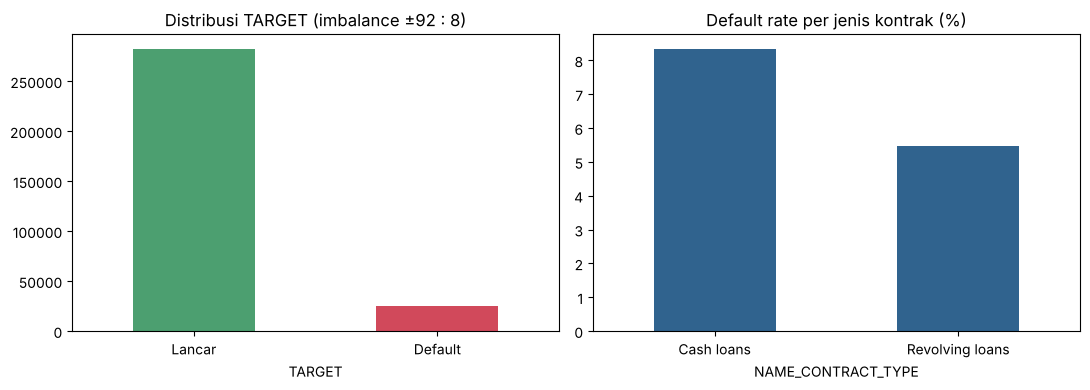

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
app.TARGET.value_counts().plot.bar(ax=ax[0], color=['#4C9F70', '#D1495B'])
ax[0].set_title('Distribusi TARGET (imbalance ±92 : 8)'); ax[0].set_xticklabels(['Lancar', 'Default'], rotation=0)
(app.groupby('NAME_CONTRACT_TYPE').TARGET.mean() * 100).plot.bar(ax=ax[1], color='#30638E')
ax[1].set_title('Default rate per jenis kontrak (%)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Kesimpulan baseline:**
- Default rate **8,07%** → inilah angka yang ingin diturunkan.
- Data sangat *imbalance* → perlu penanganan khusus saat modeling (`class_weight`, metrik AUC).
- Estimasi kerugian tahunan menjadi **acuan untuk mengukur dampak model** di notebook 04.

## 5. Analisis Biaya Kesalahan: False Negative vs False Positive

### 5.1 Kenapa perlu dihitung?
Tidak ada model yang 100% benar. Setiap kali model memutuskan *setujui* atau *tolak*, ada dua kemungkinan salah. **Kedua kesalahan itu tidak sama mahalnya**, sehingga sebelum memilih cara menilai model (metrik), kita harus tahu dulu **kesalahan mana yang paling merugikan perusahaan**.

### 5.2 Empat kemungkinan hasil keputusan
| | **Kenyataannya: nasabah lancar** | **Kenyataannya: nasabah gagal bayar** |
|---|---|---|
| **Model bilang: aman → disetujui** | **True Negative**: keputusan benar, perusahaan dapat bunga | **False Negative (FN)**: nasabah berisiko lolos, uang pinjaman hilang |
| **Model bilang: berisiko → ditolak** | **False Positive (FP)**: nasabah baik ditolak, peluang untung hilang | **True Positive**: kerugian berhasil dicegah |

> **Analogi sederhana:** Bayangkan satpam bank.
> - **FN** = satpam membiarkan pencuri masuk, sehingga **uang benar-benar hilang**.
> - **FP** = satpam menolak tamu baik-baik, sehingga **peluang bisnis hilang**, tapi uang di brankas tetap aman.
>
> Keduanya merugikan, tapi jenis kerugiannya berbeda: yang satu **kehilangan modal**, yang lain **kehilangan keuntungan**.

### 5.3 Kerugian False Negative: modal yang hilang

Ketika nasabah yang ternyata gagal bayar disetujui, perusahaan sudah menyerahkan uang pinjaman. Tidak semua uang itu hilang, karena sebagian masih bisa ditagih atau dipulihkan. Bagian yang **tidak kembali** itulah kerugiannya.

**Rumus:** `Kerugian FN = Jumlah pinjaman (EAD) × Persentase yang hilang (LGD)`

| Istilah | Arti dalam bahasa sederhana | Nilai yang dipakai | Sumber |
|---|---|---|---|
| **EAD** (*Exposure at Default*) | Besar uang yang dipinjamkan saat nasabah gagal bayar | `AMT_CREDIT` dari data | Dataset Home Credit |
| **LGD** (*Loss Given Default*) | Dari uang yang macet, berapa persen yang **tidak bisa ditagih kembali** | **45% (batas bawah)** | Basel Framework CRE32.5, standar regulator perbankan internasional. LGD 45% berlaku untuk klaim tanpa jaminan pada pendekatan foundation IRB (aslinya untuk eksposur korporasi), sehingga dipakai sebagai batas bawah yang konservatif |
| | | **75% (batas atas)** | Bahnsen et al. (2014), riset credit scoring untuk kredit konsumen tanpa jaminan |

Pinjaman Home Credit umumnya **tanpa jaminan** (tidak ada rumah/mobil yang bisa disita), sehingga porsi yang hilang saat macet cenderung besar.

### 5.4 Kerugian False Positive: keuntungan yang hilang

Ketika nasabah yang sebenarnya lancar ditolak, perusahaan **tidak kehilangan uang**, karena uangnya tidak pernah keluar. Yang hilang adalah **keuntungan bunga** yang seharusnya didapat jika pinjaman itu dicairkan.

**Rumus:** `Kerugian FP = Saldo pinjaman rata-rata × Margin bunga bersih (NIM) × Lama pinjaman (tenor)`

| Istilah | Arti dalam bahasa sederhana | Nilai yang dipakai | Sumber |
|---|---|---|---|
| **Margin bunga bersih** (proksi NIM) | Keuntungan bunga per tahun setelah dikurangi biaya dana, dibanding nilai pinjaman | **13,6% per tahun** | Proksi dari data resmi **Home Credit Indonesia 2023** (lihat 5.4.1) |
| **Tenor** | Lama pinjaman dicicil | Median **20 bulan** | Dihitung dari data: `AMT_CREDIT ÷ AMT_ANNUITY` |
| **Saldo rata-rata** | Karena dicicil tiap bulan, sisa utang terus berkurang dari 100% ke 0%, sehingga rata-ratanya kira-kira **setengah** dari pinjaman awal | `AMT_CREDIT ÷ 2` | Konsep pinjaman amortisasi (cicilan tetap) |

#### 5.4.1 Dari mana angka margin 13,6%?

Dataset yang diberikan **tidak menyebutkan negara asal maupun mata uangnya**. Karena itu yang kita ambil dari laporan keuangan adalah **persentase margin**, bukan nominal Rupiah, lalu persentase itu diterapkan ke nilai pinjaman di dataset.

**Sumber utama: PT Home Credit Indonesia (2023)**
| Komponen | Nilai | Sumber |
|---|---|---|
| Pendapatan bunga bersih (*net interest income*) | Rp 1.261.790 juta | Laporan Keberlanjutan PT Home Credit Indonesia 2023, bagian Kinerja Ekonomi (data audited) |
| Volume pembiayaan yang disalurkan sepanjang 2023 | Rp 9,3 triliun | Siaran pers Home Credit Indonesia, dikutip Kontan (12 Feb 2024) |
| **Proksi margin = 1.261,79 miliar ÷ 9.300 miliar** | **≈ 13,6%** | Perhitungan sendiri |

**Mengapa disebut proksi?** NIM resmi dihitung terhadap **saldo piutang rata-rata**, bukan volume penyaluran. Saldo piutang Home Credit Indonesia tidak tercantum di laporan tersebut, sehingga volume penyaluran dipakai sebagai pendekatan.

**Pembanding: Home Credit & Finance Bank, Rusia (2017)**
NIM resmi yang dilaporkan = **13,7%** (IFRS Consolidated Results 2017). Angkanya hampir sama dengan proksi Indonesia, sehingga margin ±13-14% **konsisten di dua negara operasi Home Credit** dan layak dipakai.

**Kenapa dibagi 2?** Contoh: pinjam 1 juta selama 10 bulan. Bulan pertama sisa utang 1 juta, bulan terakhir hampir 0, jadi rata-rata sisa utang selama 10 bulan sekitar 500 ribu. Bunga dihitung dari sisa utang ini, bukan dari 1 juta penuh.

In [5]:
full = pd.read_csv(f'{DATA_DIR}/application_train.csv', usecols=['TARGET', 'AMT_CREDIT', 'AMT_ANNUITY'])

NII_HCI_2023    = 1_261_790   # Rp juta: pendapatan bunga bersih HCI 2023 (Laporan Keberlanjutan 2023)
VOLUME_HCI_2023 = 9_300_000   # Rp juta: volume pembiayaan HCI 2023 (Kontan, 12 Feb 2024)
NIM = NII_HCI_2023 / VOLUME_HCI_2023                                # proksi margin bunga bersih ≈ 13,6%
print(f'Proksi margin bunga bersih Home Credit Indonesia 2023: {NIM:.1%}\n')
tenor_bln   = (full.AMT_CREDIT / full.AMT_ANNUITY).median()        # median tenor (bulan)
tenor_thn   = tenor_bln / 12
kredit_bad  = full.loc[full.TARGET == 1, 'AMT_CREDIT'].mean()      # rata-rata pinjaman nasabah default
kredit_good = full.loc[full.TARGET == 0, 'AMT_CREDIT'].mean()      # rata-rata pinjaman nasabah lancar

print('=== CONTOH PERHITUNGAN UNTUK 1 NASABAH RATA-RATA ===\n')
print('FALSE NEGATIVE (nasabah berisiko disetujui)')
print(f'  Rata-rata pinjaman nasabah default : {kredit_bad:>12,.0f}')
for lgd in [0.45, 0.75]:
    print(f'  x LGD {lgd:.0%}                        = {kredit_bad*lgd:>12,.0f}  <- modal yang hilang')

cost_fp = kredit_good / 2 * NIM * tenor_thn
print('\nFALSE POSITIVE (nasabah baik ditolak)')
print(f'  Rata-rata pinjaman nasabah lancar  : {kredit_good:>12,.0f}')
print(f'  Saldo rata-rata (/2)               : {kredit_good/2:>12,.0f}')
print(f'  x margin {NIM:.1%} per tahun          = {kredit_good/2*NIM:>12,.0f}  per tahun')
print(f'  x tenor {tenor_bln:.0f} bulan ({tenor_thn:.2f} tahun)    = {cost_fp:>12,.0f}  <- keuntungan yang hilang')

Proksi margin bunga bersih Home Credit Indonesia 2023: 13.6%

=== CONTOH PERHITUNGAN UNTUK 1 NASABAH RATA-RATA ===

FALSE NEGATIVE (nasabah berisiko disetujui)
  Rata-rata pinjaman nasabah default :      557,779
  x LGD 45%                        =      251,000  <- modal yang hilang
  x LGD 75%                        =      418,334  <- modal yang hilang

FALSE POSITIVE (nasabah baik ditolak)
  Rata-rata pinjaman nasabah lancar  :      602,648
  Saldo rata-rata (/2)               :      301,324
  x margin 13.6% per tahun          =       40,883  per tahun
  x tenor 20 bulan (1.67 tahun)    =       68,138  <- keuntungan yang hilang


### 5.5 Perbandingan dan uji sensitivitas

Nilai LGD sebenarnya milik Home Credit tidak dipublikasikan, jadi kita tidak memakai satu angka saja. Kita uji **tiga skenario** untuk melihat apakah kesimpulannya tetap sama.

,Skenario LGD,Kerugian 1 FN,Kerugian 1 FP,FN lebih mahal (x),1 FN setara berapa FP
0,45%,251000,68138,3.68,3
1,60%,334667,68138,4.91,4
2,75%,418334,68138,6.14,6


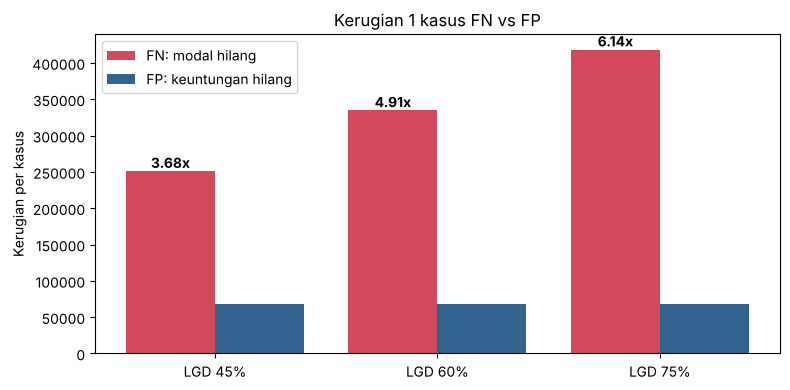

In [6]:
rows = []
for lgd in [0.45, 0.60, 0.75]:
    cost_fn = kredit_bad * lgd
    rows.append({'Skenario LGD': f'{lgd:.0%}',
                 'Kerugian 1 FN': round(cost_fn),
                 'Kerugian 1 FP': round(cost_fp),
                 'FN lebih mahal (x)': round(cost_fn / cost_fp, 2),
                 '1 FN setara berapa FP': int(cost_fn // cost_fp)})
sens = pd.DataFrame(rows)
display(sens)

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(sens))
ax.bar([i - 0.2 for i in x], sens['Kerugian 1 FN'], width=0.4, color='#D1495B', label='FN: modal hilang')
ax.bar([i + 0.2 for i in x], sens['Kerugian 1 FP'], width=0.4, color='#30638E', label='FP: keuntungan hilang')
for i, r in sens.iterrows():
    ax.text(i - 0.2, r['Kerugian 1 FN'], f"{r['FN lebih mahal (x)']}x", ha='center', va='bottom', fontweight='bold')
ax.set_xticks(list(x)); ax.set_xticklabels('LGD ' + sens['Skenario LGD'])
ax.set_ylabel('Kerugian per kasus'); ax.set_title('Kerugian 1 kasus FN vs FP')
ax.legend(); plt.tight_layout(); plt.show()

### 5.6 Titik impas: kapan sebaiknya menolak?

Dari biaya di atas, kita bisa menghitung **batas risiko** di mana menolak lebih menguntungkan daripada menyetujui:

`Tolak jika peluang default > Biaya FP ÷ (Biaya FN + Biaya FP)`

Logikanya: menyetujui seorang nasabah berarti mempertaruhkan *Biaya FN* dengan peluang sebesar PD, sedangkan menolaknya berarti pasti kehilangan *Biaya FP* jika ia ternyata nasabah baik. Titik impas adalah saat kedua risiko itu sama besar.

In [7]:
for lgd in [0.45, 0.60, 0.75]:
    cost_fn = kredit_bad * lgd
    print(f'LGD {lgd:.0%}: tolak jika peluang default > {cost_fp/(cost_fn+cost_fp):.1%}')

LGD 45%: tolak jika peluang default > 21.4%
LGD 60%: tolak jika peluang default > 16.9%
LGD 75%: tolak jika peluang default > 14.0%


Artinya, perusahaan **sudah layak menolak** nasabah yang peluang gagal bayarnya sekitar **14-21%**, jauh di bawah 50% (threshold default model). Angka ini menjadi **acuan awal** saat menentukan threshold di NB 04, bukan keputusan akhir.

### 5.7 Kesimpulan untuk stakeholder

| Temuan | Arti bagi bisnis |
|---|---|
| 1 kasus FN **3,7-6,1× lebih mahal** daripada 1 kasus FP | Meloloskan 1 nasabah berisiko sama ruginya dengan menolak **3-6 nasabah baik** |
| Kesimpulan sama di semua skenario LGD | Keputusan ini **tidak bergantung** pada asumsi yang tidak pasti |
| Titik impas penolakan ±14-21% | Model harus lebih "berhati-hati", tapi tetap tidak boleh menolak terlalu banyak |

**Implikasi pada cara menilai model:**
- **Prioritas: menangkap sebanyak mungkin calon gagal bayar**, yaitu **Recall** tinggi.
- Tapi tidak dengan menolak semua orang, karena kalau terlalu banyak nasabah baik ditolak, kerugian FP menumpuk dan menjadi besar juga.
- Karena itu dipakai **F2-score**, metrik yang menyeimbangkan keduanya tetapi **memberi bobot lebih pada Recall**. Ini sesuai dengan temuan bahwa FN jauh lebih mahal.
- Untuk membandingkan model dipakai **PR-AUC**, yang mengukur kemampuan model menemukan nasabah gagal bayar di data yang mayoritasnya nasabah lancar (92:8).
- **Guardrail:** F2 tidak memperhitungkan keuntungan dari nasabah baik yang disetujui, sehingga threshold F2 tertinggi bisa saja menolak terlalu banyak nasabah dan justru menaikkan biaya. Karena itu threshold dipilih sebagai **F2 tertinggi di antara threshold yang total biayanya tidak lebih buruk dari kondisi tanpa model**, dengan total biaya = jumlah FN × biaya FN + jumlah FP × biaya FP.

**Catatan kehati-hatian:**
- Margin 13,6% adalah **proksi** dari Home Credit Indonesia 2023 (pendapatan bunga bersih ÷ volume penyaluran), karena saldo piutang tidak dipublikasikan. Pembandingnya, NIM resmi Home Credit Rusia 2017 = 13,7%.
- Negara asal dan mata uang dataset tidak diungkapkan, sehingga yang dipakai adalah **persentase**, bukan nominal Rupiah.
- Margin bunga bersih adalah angka **sebelum biaya operasional**, sehingga keuntungan yang hilang sebenarnya lebih kecil, dan FN sebenarnya bisa **lebih** mahal dari perhitungan ini. Kesimpulannya tetap sama.
- Kerangka perhitungan (FN = pinjaman × LGD; FP = keuntungan yang hilang) mengikuti Bahnsen, Aouada & Ottersten (2014).

## 6. Pemahaman Data (Data Landscape)

| Tabel | Granularity | Ukuran | Isi |
|---|---|---|---|
| `application_train/test` | 1 baris = 1 pengajuan | 166 MB / 26 MB | Data utama: demografi, pendapatan, pinjaman, `TARGET` |
| `bureau` | 1 baris = 1 kredit di lembaga lain | 170 MB | Riwayat kredit dari Credit Bureau |
| `bureau_balance` | 1 baris = 1 bulan per kredit bureau | 376 MB | Status bulanan kredit bureau |
| `previous_application` | 1 baris = 1 pengajuan lama di Home Credit | 405 MB | Riwayat pengajuan (disetujui/ditolak) |
| `POS_CASH_balance` | 1 baris = 1 bulan per pinjaman POS/cash | 393 MB | Saldo bulanan pinjaman lama |
| `credit_card_balance` | 1 baris = 1 bulan per kartu kredit | 425 MB | Saldo bulanan kartu kredit |
| `installments_payments` | 1 baris = 1 pembayaran cicilan | 723 MB | Riwayat pembayaran (tepat/terlambat) |

**Relasi antar tabel (ERD sederhana):**
```
                         application_train/test  (SK_ID_CURR)
                 ┌───────────────┴────────────────┐
           bureau (SK_ID_CURR)              previous_application (SK_ID_CURR, SK_ID_PREV)
                 │                       ┌─────────────┼──────────────────┐
        bureau_balance (SK_ID_BUREAU)  POS_CASH_balance  installments_payments  credit_card_balance
                                          (SK_ID_PREV)
```
Tabel pendukung bersifat **one-to-many**, jadi harus **diagregasi ke level `SK_ID_CURR`** sebelum digabung. Ini tugas utama notebook ETL. Total data ±2,6 GB.

**Anomali awal yang sudah teridentifikasi** (ditangani di notebook 02):
- `DAYS_EMPLOYED = 365243` (±1000 tahun) pada **55.374** baris, placeholder untuk pensiunan/tidak bekerja.
- `CODE_GENDER = 'XNA'` pada 4 baris.
- `AMT_INCOME_TOTAL` maksimum 117 juta, outlier ekstrem.
- **41 kolom** dengan missing value > 50% (mayoritas data properti bangunan).
- Kolom `DAYS_*` bernilai negatif (relatif terhadap tanggal pengajuan).

## 7. Hipotesis Awal

| # | Hipotesis | Kolom terkait |
|---|---|---|
| H1 | Nasabah lebih muda punya risiko default lebih tinggi | `DAYS_BIRTH` |
| H2 | Skor eksternal rendah ↔ risiko tinggi (prediktor terkuat) | `EXT_SOURCE_1/2/3` |
| H3 | Rasio cicilan terhadap pendapatan tinggi → risiko naik | `AMT_ANNUITY / AMT_INCOME_TOTAL` |
| H4 | Pendidikan lebih rendah & pekerjaan *low-skill* → risiko naik | `NAME_EDUCATION_TYPE`, `OCCUPATION_TYPE` |
| H5 | Masa kerja singkat → risiko naik | `DAYS_EMPLOYED` |
| H6 | Riwayat pengajuan ditolak / sering telat bayar → risiko naik | `previous_application`, `installments_payments` |
| H7 | Wilayah dengan rating buruk → risiko naik | `REGION_RATING_CLIENT` |

## 8. Stakeholder Utama: Credit Risk Management

| Aspek | Penjelasan |
|---|---|
| **Siapa** | Tim Credit Risk Management, pemilik kebijakan persetujuan kredit dan penanggung jawab NPL / *credit loss* |
| **Keputusan yang diambil** | Menetapkan *cut-off* skor: siapa yang di-approve, di-review manual, atau ditolak |
| **Pertanyaan mereka** | "Nasabah seperti apa yang berisiko?", "Di threshold berapa kerugian paling kecil?", "Berapa nasabah baik yang ikut tertolak?" |
| **Output untuk mereka** | Insight risiko per segmen (NB 03), model PD + rekomendasi threshold (NB 04), dashboard Power BI, aplikasi Streamlit |

## 9. Rancangan EDA (Notebook 03)

EDA dilakukan **sebelum modeling** untuk tiga tujuan: (1) memastikan data layak dipakai, (2) memahami pola risiko, dan (3) **membuktikan bahwa model memang dibutuhkan**.

### 9.1 Data Profiling
| Cek | Isi |
|---|---|
| Struktur | Jumlah baris/kolom, tipe data, memori |
| Kamus fitur | Kelompokkan 122 kolom: demografi, finansial, pekerjaan, properti, dokumen, biro kredit, skor eksternal |
| Kelengkapan | % missing per kolom & per kelompok fitur |
| Keunikan | Duplikat `SK_ID_CURR`, kardinalitas kolom kategorik |
| Distribusi | Histogram numerik, frekuensi kategorik, proporsi `TARGET` |

### 9.2 Data Quality Check
| Cek | Contoh temuan awal | Rencana penanganan |
|---|---|---|
| Nilai tidak masuk akal | `DAYS_EMPLOYED = 365243` (55.374 baris) | Ganti NaN + flag `IS_UNEMPLOYED/PENSIONER` |
| Kategori tidak valid | `CODE_GENDER = XNA`, `NAME_FAMILY_STATUS = Unknown` | Jadikan NaN / modus |
| Outlier | `AMT_INCOME_TOTAL` maks 117 juta | Cek wajar/tidak, *capping* (winsorize) atau log transform |
| Missing tinggi | 41 kolom > 50% | Drop / flag missing, berdasarkan IV |
| Konsistensi | `AMT_GOODS_PRICE` > `AMT_CREDIT`?, umur < 18? | Validasi logika bisnis |
| Train vs test | Distribusi fitur kunci berbeda? | Bandingkan untuk deteksi *data drift* |

### 9.3 Analisis Statistik
- **Statistik deskriptif** per kelas TARGET (mean, median, std, skewness).
- **Uji signifikansi:** Chi-square (kategorik) dan Mann-Whitney U (numerik, karena data tidak normal), dengan α = 0,05.
- **Korelasi:** Spearman antar fitur numerik dan **VIF** untuk multikolinearitas (penting untuk Logistic Regression).
- **Information Value (IV) / WoE:** meranking kekuatan prediktif fitur (standar industri credit scoring).

### 9.4 Business Analysis
Menjawab **Objective 1**: *profil nasabah seperti apa yang berisiko gagal bayar, dan apa action-nya bagi Credit Risk?* Metrik analisisnya adalah **default rate per segmen** dibandingkan baseline 8,07%, serta **porsi segmen** terhadap total pengajuan.

| # | Pertanyaan bisnis | Hipotesis | Fitur | Analisis & visual | Contoh action bila terbukti |
|---|---|---|---|---|---|
| Q1 | Seberapa kuat skor eksternal membedakan nasabah? | H2 | `EXT_SOURCE_1/2/3` | Default rate per desil skor, KDE TARGET 0 vs 1 | Jadikan skor eksternal syarat *pre-screening* |
| Q2 | Apakah usia memengaruhi risiko? | H1 | `DAYS_BIRTH` → kelompok umur | Default rate per kelompok umur + porsi pengajuan | Limit awal lebih kecil untuk nasabah muda, naik bertahap jika lancar |
| Q3 | Apakah beban cicilan terlalu berat memicu default? | H3 | `AMT_ANNUITY / AMT_INCOME_TOTAL`, `AMT_CREDIT / AMT_INCOME_TOTAL` | Default rate per kuantil rasio | Batas maksimum rasio cicilan dalam kebijakan approval |
| Q4 | Profil sosial-ekonomi mana yang paling berisiko/aman? | H4 | `NAME_EDUCATION_TYPE`, `OCCUPATION_TYPE`, `NAME_INCOME_TYPE` | Default rate vs porsi segmen | Campaign akuisisi ke segmen risiko rendah yang porsinya kecil |
| Q5 | Apakah stabilitas kerja berpengaruh? | H5 | `DAYS_EMPLOYED` → masa kerja | Default rate per kelompok masa kerja | Syarat minimal masa kerja / dokumen tambahan |
| Q6 | Apakah riwayat di Home Credit memprediksi perilaku? | H6 | `previous_application` (% ditolak), `installments_payments` (% telat bayar) | Default rate per kelompok riwayat | *Fast-track* bagi nasabah lama yang lancar |
| Q7 | Wilayah mana yang berisiko? | H7 | `REGION_RATING_CLIENT_W_CITY` | Default rate per rating wilayah | Kebijakan berbeda per wilayah |

**Bukti kebutuhan model (justifikasi modeling):** simulasi kebijakan *rule-based* sederhana (misalnya tolak jika `EXT_SOURCE` rendah, atau tolak jika umur < 25) lalu hitung Recall, F2, dan total biaya. Jika satu fitur saja hanya menangkap sebagian kecil default atau terlalu banyak menolak nasabah baik, berarti risiko ditentukan **kombinasi banyak faktor**, dan itu yang menjadi alasan dibutuhkannya model machine learning.

### 9.5 Dashboard Power BI
Data ringkasan hasil EDA diekspor untuk dashboard monitoring risiko bagi Credit Risk:
- **KPI card:** jumlah pengajuan, default rate, eksposur default, estimasi kerugian
- Default rate per segmen (umur, pendidikan, pekerjaan, wilayah, rasio cicilan)
- Distribusi skor eksternal per TARGET
- Slicer: jenis kontrak, gender, tipe pendapatan

### 9.6 Output EDA
1. Laporan kualitas data + keputusan cleaning → input NB 04
2. **Top 2 insight + action** (sesuai pedoman PPT), dipilih dari segmen dengan selisih default rate besar **dan** porsi signifikan
3. Daftar fitur dengan IV tinggi & fitur yang perlu di-drop → input feature engineering
4. Dashboard Power BI

## 10. Rancangan Modeling (Notebook 04)

| Tahap | Rencana |
|---|---|
| **Split data** | Stratified train / validation (80:20), lalu *stratified K-fold CV* di train |
| **Preprocessing** | Imputasi (median / modus / flag missing), encoding (one-hot / target / WoE), scaling untuk LogReg, penanganan outlier |
| **Feature engineering** | Rasio: credit/income, annuity/income, credit/goods, annuity/credit (tenor); umur & masa kerja (tahun); agregasi rata-rata `EXT_SOURCE`; agregasi tabel pendukung (jumlah pengajuan ditolak, rata-rata hari telat bayar, utang aktif di bureau) |
| **Feature selection** | IV, korelasi/VIF, feature importance |
| **Model** | **Logistic Regression** (baseline, interpretable, standar scorecard), **Random Forest**, **LightGBM** |
| **Imbalance** | `class_weight='balanced'` / `scale_pos_weight` (tanpa oversampling data validasi) |
| **Tuning** | `RandomizedSearchCV` dengan scoring = **average precision (PR-AUC)** |
| **Evaluasi** | PR curve & **PR-AUC** (pilih model), **F2-score dengan guardrail biaya** (pilih threshold), Recall/Precision, confusion matrix, ROC-AUC sebagai pembanding |
| **Interpretasi** | Koefisien LogReg / feature importance / SHAP: faktor apa yang mendorong risiko |
| **Business impact** | Lihat Bagian 11 |
| **Output** | `model.pkl`, risk band, file submission `application_test` |

## 11. Rancangan Pengukuran Dampak Bisnis

Setelah model terbaik dan threshold-nya diperoleh, dampak model diukur dengan **membandingkan kebijakan sebelum dan sesudah model pada data validasi yang sama**.

### 11.1 Skenario pembanding
| | Sebelum model (baseline) | Sesudah model |
|---|---|---|
| Kebijakan | Semua pengajuan disetujui (kondisi data historis) | Tolak / review jika PD ≥ threshold |
| Kerugian kredit | Σ semua default × EAD × LGD | Σ **FN** × EAD × LGD |
| Biaya peluang | 0 | Σ **FP** × NIM × saldo rata-rata × tenor |
| **Total biaya** | Kerugian kredit | Kerugian kredit + biaya peluang |

Biaya FP wajib ikut dihitung. Tanpa itu, kebijakan "tolak semua" akan terlihat terbaik karena kerugian kreditnya nol.

### 11.2 Formula
- `Biaya_FN_i = AMT_CREDIT_i × LGD`
- `Biaya_FP_i = AMT_CREDIT_i / 2 × NIM × tenor_i`, dengan `tenor_i = AMT_CREDIT_i / AMT_ANNUITY_i` (bulan) / 12
- `Total biaya = Σ Biaya_FN + Σ Biaya_FP`
- `Penghematan = Total biaya baseline − Total biaya model` (nominal & %)

Biaya dihitung **per nasabah** (berdasarkan pinjamannya masing-masing), bukan memakai rata-rata, sehingga lebih akurat.

### 11.3 Metrik yang dibandingkan
| Metrik | Sebelum | Sesudah |
|---|---|---|
| Default rate pinjaman disetujui | baseline | hasil model |
| Total biaya & penghematan | baseline | hasil model |
| Approval rate (guardrail) | 100% | hasil model |
| Jumlah nasabah baik tertolak (guardrail) | 0 | hasil model |

### 11.4 Analisis pendukung
- **Kurva F2 dan total biaya vs threshold**: memilih threshold F2 tertinggi yang memenuhi guardrail biaya, dan membandingkannya dengan threshold biaya minimum.
- **Sensitivitas LGD 45% / 60% / 75%**: memastikan kesimpulan tetap berlaku di seluruh rentang asumsi.
- **Simulasi 3 zona** (Approve / Review manual / Reject): dampak jika pengajuan di zona tengah dinilai manual oleh analis.

### 11.5 Keterbatasan
Dataset hanya berisi pinjaman yang dulu **disetujui**. Pengajuan yang ditolak tidak memiliki label (*reject inference*), sehingga dampak pada populasi pengajuan baru dapat berbeda.

## 12. Arsitektur Solusi

```
CSV mentah (8 tabel, ±2,6 GB)
   │  Extract
   ▼
Transform (pandas): perbaikan tipe, anomali, agregasi per SK_ID_CURR
   │
   ▼
Parquet (staging lokal) ──Load──► BigQuery  [raw tables + mart table 1 baris/nasabah]
                                     │
                     ┌───────────────┴───────────────┐
              NB 03 EDA ──► Power BI           NB 04 Modeling
                                                     │
                                               model.pkl ──► NB 05 Streamlit app
```

## 13. Asumsi & Batasan
- Data bersifat historis dan statis (snapshot). Tanggal disajikan relatif (`DAYS_*`), bukan tanggal kalender.
- Mata uang tidak disebutkan, jadi nilai uang disajikan dalam unit dataset.
- Negara asal dan mata uang dataset tidak diungkapkan. Nilai uang disajikan dalam unit dataset, dan parameter dari laporan keuangan dipakai dalam bentuk **persentase**.
- LGD tidak dipublikasikan, sehingga dipakai rentang **45-75%** dengan analisis sensitivitas.
- Margin bunga bersih 13,6% adalah **proksi** dari Home Credit Indonesia 2023, dengan pembanding NIM resmi Home Credit Rusia 2017 (13,7%).
- Pendapatan bunga per pinjaman tidak tersedia, sehingga *opportunity cost* nasabah baik yang tertolak dihitung dalam jumlah nasabah/eksposur, bukan profit.
- `application_test` tidak memiliki `TARGET`, sehingga evaluasi dilakukan pada validation set dari data train.

## 14. Referensi
1. Home Credit Group, profil perusahaan: https://www.homecredit.net
2. Basel Committee on Banking Supervision (2017). *Basel III: Finalising post-crisis reforms*: komponen PD, LGD, EAD
3. Siddiqi, N. (2017). *Intelligent Credit Scoring*, 2nd ed. Wiley
4. PT Home Credit Indonesia (2024). *Laporan Keberlanjutan 2023*: https://www.homecredit.co.id/static/pdf/Laporan_Keberlanjutan_PT_Home_Credit_Indonesia_Tahun_2023_.pdf
5. Kontan (12 Feb 2024). *Home Credit Catatkan Pembiayaan Rp 9,3 Triliun Sepanjang Tahun Lalu*: https://keuangan.kontan.co.id/news/home-credit-catatkan-pembiayaan-rp-93-triliun-sepanjang-tahun-lalu
6. Home Credit & Finance Bank (2018). *IFRS Consolidated Results for 2017*: https://www.homecredit.net/wp-content/uploads/2022/11/ifrs-consolidated-results-for-the-12-month-period-ended-31-dec-2017.pdf
7. BIS, Basel Framework CRE32: https://www.bis.org/committees/bcbs/basel-framework/81396/chapter.pdf
8. Bahnsen, A. C., Aouada, D., Ottersten, B. (2014). *Example-Dependent Cost-Sensitive Logistic Regression for Credit Scoring*. IEEE ICMLA
9. Saito, T., Rehmsmeier, M. (2015). *The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets*. PLoS ONE 10(3)
10. Thomas, L., Crook, J., Edelman, D. (2017). *Credit Scoring and Its Applications*, 2nd ed. SIAM